In [ ]:
# Nature-style matplotlib settings
import os
import pandas as pd
import glob
import matplotlib as mpl
import matplotlib.pyplot as plt

RENDER_MODE = "matplotlib"  # "matplotlib" | "pycairo_pdf"
PDF_OUTPUT_DIR = "/work/upcorreia/users/wenckste/Bindome/Figures/1A_coverage"

def set_nature_style():
    mpl.rcParams.update({
        # Font
        "font.family": "sans-serif",
        "font.sans-serif": ["Arial", "Helvetica", "DejaVu Sans"],
        "font.size": 8,

        # Figure size (Nature)
        "figure.figsize": (3.5, 2.5),
        "figure.dpi": 300,

        # Axes
        "axes.linewidth": 0.8,
        "axes.labelsize": 8,
        "axes.titlesize": 8,

        # Ticks
        "xtick.labelsize": 7,
        "ytick.labelsize": 7,
        "xtick.direction": "out",
        "ytick.direction": "out",
        "xtick.major.size": 3,
        "ytick.major.size": 3,
        "xtick.major.width": 0.8,
        "ytick.major.width": 0.8,

        # Lines
        "lines.linewidth": 1.2,
        "lines.markersize": 4,

        # Legend
        "legend.fontsize": 7,
        "legend.frameon": False,

        # Grid (usually minimal or off in Nature)
        "axes.grid": False,

        # Spines
        "axes.spines.top": False,
        "axes.spines.right": False,

        # Save
        "savefig.bbox": "tight",
        "savefig.pad_inches": 0.02
    })

def finalize_figure(fig, filename_stem, dpi=600):
    if RENDER_MODE == "matplotlib":
        plt.show()
        return

    if RENDER_MODE == "pycairo_pdf":
        try:
            from matplotlib.backends.backend_cairo import FigureCanvasCairo
            os.makedirs(PDF_OUTPUT_DIR, exist_ok=True)
            out_path = os.path.join(PDF_OUTPUT_DIR, f"{filename_stem}.pdf")
            FigureCanvasCairo(fig)
            fig.savefig(out_path, format="pdf", dpi=dpi)
            plt.close(fig)
            print(f"Exported PDF (cairo): {out_path}")
            return
        except Exception as exc:
            print(f"Cairo export failed ({exc}). Falling back to matplotlib display.")
            plt.show()
            return

    raise ValueError("RENDER_MODE must be 'matplotlib' or 'pycairo_pdf'.")

# Apply style
set_nature_style()

In [2]:


design_csv_paths = '/work/upcorreia/users/wenckste/Bindome/Data/Binders/statistics/final_design_stats_overall_sweep_combined.csv'
filtered_target_csv_paths = '/work/upcorreia/users/wenckste/Bindome/Data/Filtered/filtered_domain_stats.csv'
full_target_csv_paths = '/work/upcorreia/users/wenckste/Bindome/Data/AFDB_v6/Statistics/domain_stats.csv'

design_statistics_df = pd.read_csv(design_csv_paths)
filtered_target_statistics_df = pd.read_csv(filtered_target_csv_paths)
full_target_statistics_df = pd.read_csv(full_target_csv_paths)

design_statistics_df['Target'] = design_statistics_df['Design'].str.split('_').str[0]
design_statistics_df['Target_Domain'] = design_statistics_df['Design'].str.split('-').str[0]
# annotate membrane protein in design_statistics_df
design_statistics_df = design_statistics_df.merge(full_target_statistics_df[['uniprot', 'is_membrane_protein']].drop_duplicates('uniprot'), left_on='Target', right_on='uniprot', how='left').drop(columns=['uniprot'])

/tmp/ipykernel_2485596/3593302971.py:9: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  design_statistics_df['Target'] = design_statistics_df['Design'].str.split('_').str[0]


/tmp/ipykernel_2485596/3593302971.py:10: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  design_statistics_df['Target_Domain'] = design_statistics_df['Design'].str.split('-').str[0]


### Expand targetable proteome with new IDP gap-crop targets

In [3]:
# New IDP gap-crop targets (two-pass gap cropping, >=57aa and >=30aa) that
# expand the targetable proteome beyond the structured-domain filtered set.
combined_crops_csv_path = '/work/upcorreia/users/jkuhn/idp_bindcraft/settings/combined_twopass_crops.csv'
combined_crops_df = pd.read_csv(combined_crops_csv_path)

n_new_crop_targets = combined_crops_df['uniprot'].nunique()
n_new_targets_not_yet_targetable = len(
    set(combined_crops_df['uniprot'].dropna().unique())
    - set(filtered_target_statistics_df['uniprot'].dropna().unique())
)
print(f"Gap-crop targets loaded: {len(combined_crops_df)} crops across {n_new_crop_targets} uniprots")
print(f"  of which {n_new_targets_not_yet_targetable} uniprots are newly targetable (not already in filtered_target_statistics_df)")

# Annotate membrane status the same way the other dataframes are annotated
combined_crops_df = combined_crops_df.merge(
    full_target_statistics_df[['uniprot', 'is_membrane_protein']].drop_duplicates('uniprot'),
    on='uniprot', how='left'
)

# Extend the targetable proteome: union of the original filtered (structured) domains
# and the new IDP gap-crop domains, deduplicated on (uniprot, domain_name)
filtered_target_statistics_df = pd.concat(
    [filtered_target_statistics_df, combined_crops_df],
    ignore_index=True, sort=False
).drop_duplicates(subset=['uniprot', 'domain_name'])

print(f"Expanded targetable proteome: {filtered_target_statistics_df['uniprot'].nunique()} uniprots, "
      f"{filtered_target_statistics_df['domain_name'].nunique()} domains")

Gap-crop targets loaded: 18553 crops across 9464 uniprots
  of which 4654 uniprots are newly targetable (not already in filtered_target_statistics_df)
Expanded targetable proteome: 15318 uniprots, 32068 domains


### Coverage relative to full, targetable, soluble and insoluble proteome

In [4]:
# Number of targets in the full (soluble+insoluble) proteome
print("Entire Proteome:")
print(f"Number of targets in full proteome: {len(full_target_statistics_df['uniprot'].unique())}")
print(f"Number of targets in soluble proteome: {full_target_statistics_df[full_target_statistics_df['is_membrane_protein'] == False]['uniprot'].nunique()}")
print(f"Number of targets in insoluble proteome: {full_target_statistics_df[full_target_statistics_df['is_membrane_protein'] == True]['uniprot'].nunique()}")
print(f"Number of target domains in full proteome: {len(full_target_statistics_df['domain_name'].unique())}")
print(f"Number of target domains in soluble proteome: {len(full_target_statistics_df[full_target_statistics_df['is_membrane_protein'] == False]['domain_name'].unique())}")
print(f"Number of target domains in insoluble proteome: {len(full_target_statistics_df[full_target_statistics_df['is_membrane_protein'] == True]['domain_name'].unique())}")
print("Targetable Proteome:")
print(f"Number of targets in targetable proteome: {len(filtered_target_statistics_df['uniprot'].unique())}")
print(f'Number of targets in soluble targetable proteome: {len(filtered_target_statistics_df[filtered_target_statistics_df["is_membrane_protein"] == False]["uniprot"].unique())}')
print(f'Number of targets in insoluble targetable proteome: {len(filtered_target_statistics_df[filtered_target_statistics_df["is_membrane_protein"] == True]["uniprot"].unique())}')
print(f"Number of target domains in targetable proteome: {len(filtered_target_statistics_df['domain_name'].unique())}")
print(f"Number of target domains in soluble targetable proteome: {len(filtered_target_statistics_df[filtered_target_statistics_df['is_membrane_protein'] == False]['domain_name'].unique())}")
print(f"Number of target domains in insoluble targetable proteome: {len(filtered_target_statistics_df[filtered_target_statistics_df['is_membrane_protein'] == True]['domain_name'].unique())}")
print(f"Binders:")
print(f"Number of designed binders: {len(design_statistics_df)}")
print(f"Number of targets covered by binders: {len(design_statistics_df['Target'].unique())}")
print(f"Number of target domains covered by binders: {len(design_statistics_df['Target_Domain'].unique())}")
print(f'Average number of binders per target: {design_statistics_df.groupby("Target").size().mean():.2f}')
print(f'Average number of binders per target domain: {design_statistics_df.groupby("Target_Domain").size().mean():.2f}')
print(f"Target Coverage:")
print(f"Percentage of covered targets in full proteome: {len(design_statistics_df['Target'].unique()) / len(full_target_statistics_df['uniprot'].unique()) * 100:.2f}%")
print(f"Percentage of covered soluble targets in full soluble proteome: {len(design_statistics_df[design_statistics_df['is_membrane_protein'] == False]['Target'].unique()) / full_target_statistics_df[full_target_statistics_df['is_membrane_protein'] == False]['uniprot'].nunique() * 100:.2f}%")  
print(f"Percentage of covered insoluble targets in full insoluble proteome: {len(design_statistics_df[design_statistics_df['is_membrane_protein'] == True]['Target'].unique()) / full_target_statistics_df[full_target_statistics_df['is_membrane_protein'] == True]['uniprot'].nunique() * 100:.2f}%")
print(f"Percentage of covered targets in targetable proteome: {len(design_statistics_df['Target'].unique()) / len(filtered_target_statistics_df['uniprot'].unique()) * 100:.2f}%")
print(f"Percentage of covered soluble targets in soluble targetable proteome: {len(design_statistics_df[design_statistics_df['is_membrane_protein'] == False]['Target'].unique()) / len(filtered_target_statistics_df[filtered_target_statistics_df['is_membrane_protein'] == False]['uniprot'].unique()) * 100:.2f}%")
print(f"Percentage of covered insoluble targets in insoluble targetable proteome: {len(design_statistics_df[design_statistics_df['is_membrane_protein'] == True]['Target'].unique()) / len(filtered_target_statistics_df[filtered_target_statistics_df['is_membrane_protein'] == True]['uniprot'].unique()) * 100:.2f}%")
print(f"Domain Coverage:")
print(f"Percentage of covered target domains in full proteome: {len(design_statistics_df['Target_Domain'].unique()) / len(full_target_statistics_df['domain_name'].unique()) * 100:.2f}%")
print(f"Percentage of covered soluble target domains in full soluble proteome: {len(design_statistics_df[design_statistics_df['is_membrane_protein'] == False]['Target_Domain'].unique()) / len(full_target_statistics_df[full_target_statistics_df['is_membrane_protein'] == False]['domain_name'].unique()) * 100:.2f}%")
print(f"Percentage of covered insoluble target domains in full insoluble proteome: {len(design_statistics_df[design_statistics_df['is_membrane_protein'] == True]['Target_Domain'].unique()) / len(full_target_statistics_df[full_target_statistics_df['is_membrane_protein'] == True]['domain_name'].unique()) * 100:.2f}%")
print(f"Percentage of covered target domains in targetable proteome: {len(design_statistics_df['Target_Domain'].unique()) / len(filtered_target_statistics_df['domain_name'].unique()) * 100:.2f}%")
print(f"Percentage of covered soluble target domains in soluble targetable proteome: {len(design_statistics_df[design_statistics_df['is_membrane_protein'] == False]['Target_Domain'].unique()) / len(filtered_target_statistics_df[filtered_target_statistics_df['is_membrane_protein'] == False]['domain_name'].unique()) * 100:.2f}%")
print(f"Percentage of covered insoluble target domains in insoluble targetable proteome: {len(design_statistics_df[design_statistics_df['is_membrane_protein'] == True]['Target_Domain'].unique()) / len(filtered_target_statistics_df[filtered_target_statistics_df['is_membrane_protein'] == True]['domain_name'].unique()) * 100:.2f}%")
print(f"Target Fractions:")
print(f"Fraction of soluble targets in full proteome: {len(full_target_statistics_df[full_target_statistics_df['is_membrane_protein'] == False]['uniprot'].unique()) / len(full_target_statistics_df['uniprot'].unique()) * 100:.2f}%")
print(f"Fraction of insoluble targets in full proteome: {len(full_target_statistics_df[full_target_statistics_df['is_membrane_protein'] == True]['uniprot'].unique()) / len(full_target_statistics_df['uniprot'].unique()) * 100:.2f}%")
print(f"Fraction of targetable targets in full proteome: {len(filtered_target_statistics_df['uniprot'].unique()) / len(full_target_statistics_df['uniprot'].unique()) * 100:.2f}%")
print(f"Fraction of non-targetable targets in full proteome: {(len(full_target_statistics_df['uniprot'].unique()) - len(filtered_target_statistics_df['uniprot'].unique())) / len(full_target_statistics_df['uniprot'].unique()) * 100:.2f}%")

Entire Proteome:
Number of targets in full proteome: 20279
Number of targets in soluble proteome: 12607
Number of targets in insoluble proteome: 7672
Number of target domains in full proteome: 105981


Number of target domains in soluble proteome: 71739
Number of target domains in insoluble proteome: 34242
Targetable Proteome:
Number of targets in targetable proteome: 15318
Number of targets in soluble targetable proteome: 10580


Number of targets in insoluble targetable proteome: 4738
Number of target domains in targetable proteome: 32068
Number of target domains in soluble targetable proteome: 22949
Number of target domains in insoluble targetable proteome: 9119
Binders:
Number of designed binders: 306151
Number of targets covered by binders: 8296
Number of target domains covered by binders: 10222


Average number of binders per target: 36.90


Average number of binders per target domain: 29.95
Target Coverage:
Percentage of covered targets in full proteome: 40.91%


Percentage of covered soluble targets in full soluble proteome: 47.33%


... (3 outputs left out)

Percentage of covered soluble target domains in full soluble proteome: 10.21%


Percentage of covered insoluble target domains in full insoluble proteome: 8.47%
Percentage of covered target domains in targetable proteome: 31.88%


Percentage of covered soluble target domains in soluble targetable proteome: 31.91%


Percentage of covered insoluble target domains in insoluble targetable proteome: 31.80%
Target Fractions:
Fraction of soluble targets in full proteome: 62.17%
Fraction of insoluble targets in full proteome: 37.83%
Fraction of targetable targets in full proteome: 75.54%
Fraction of non-targetable targets in full proteome: 24.46%


### Pie-chart illustrating coverage

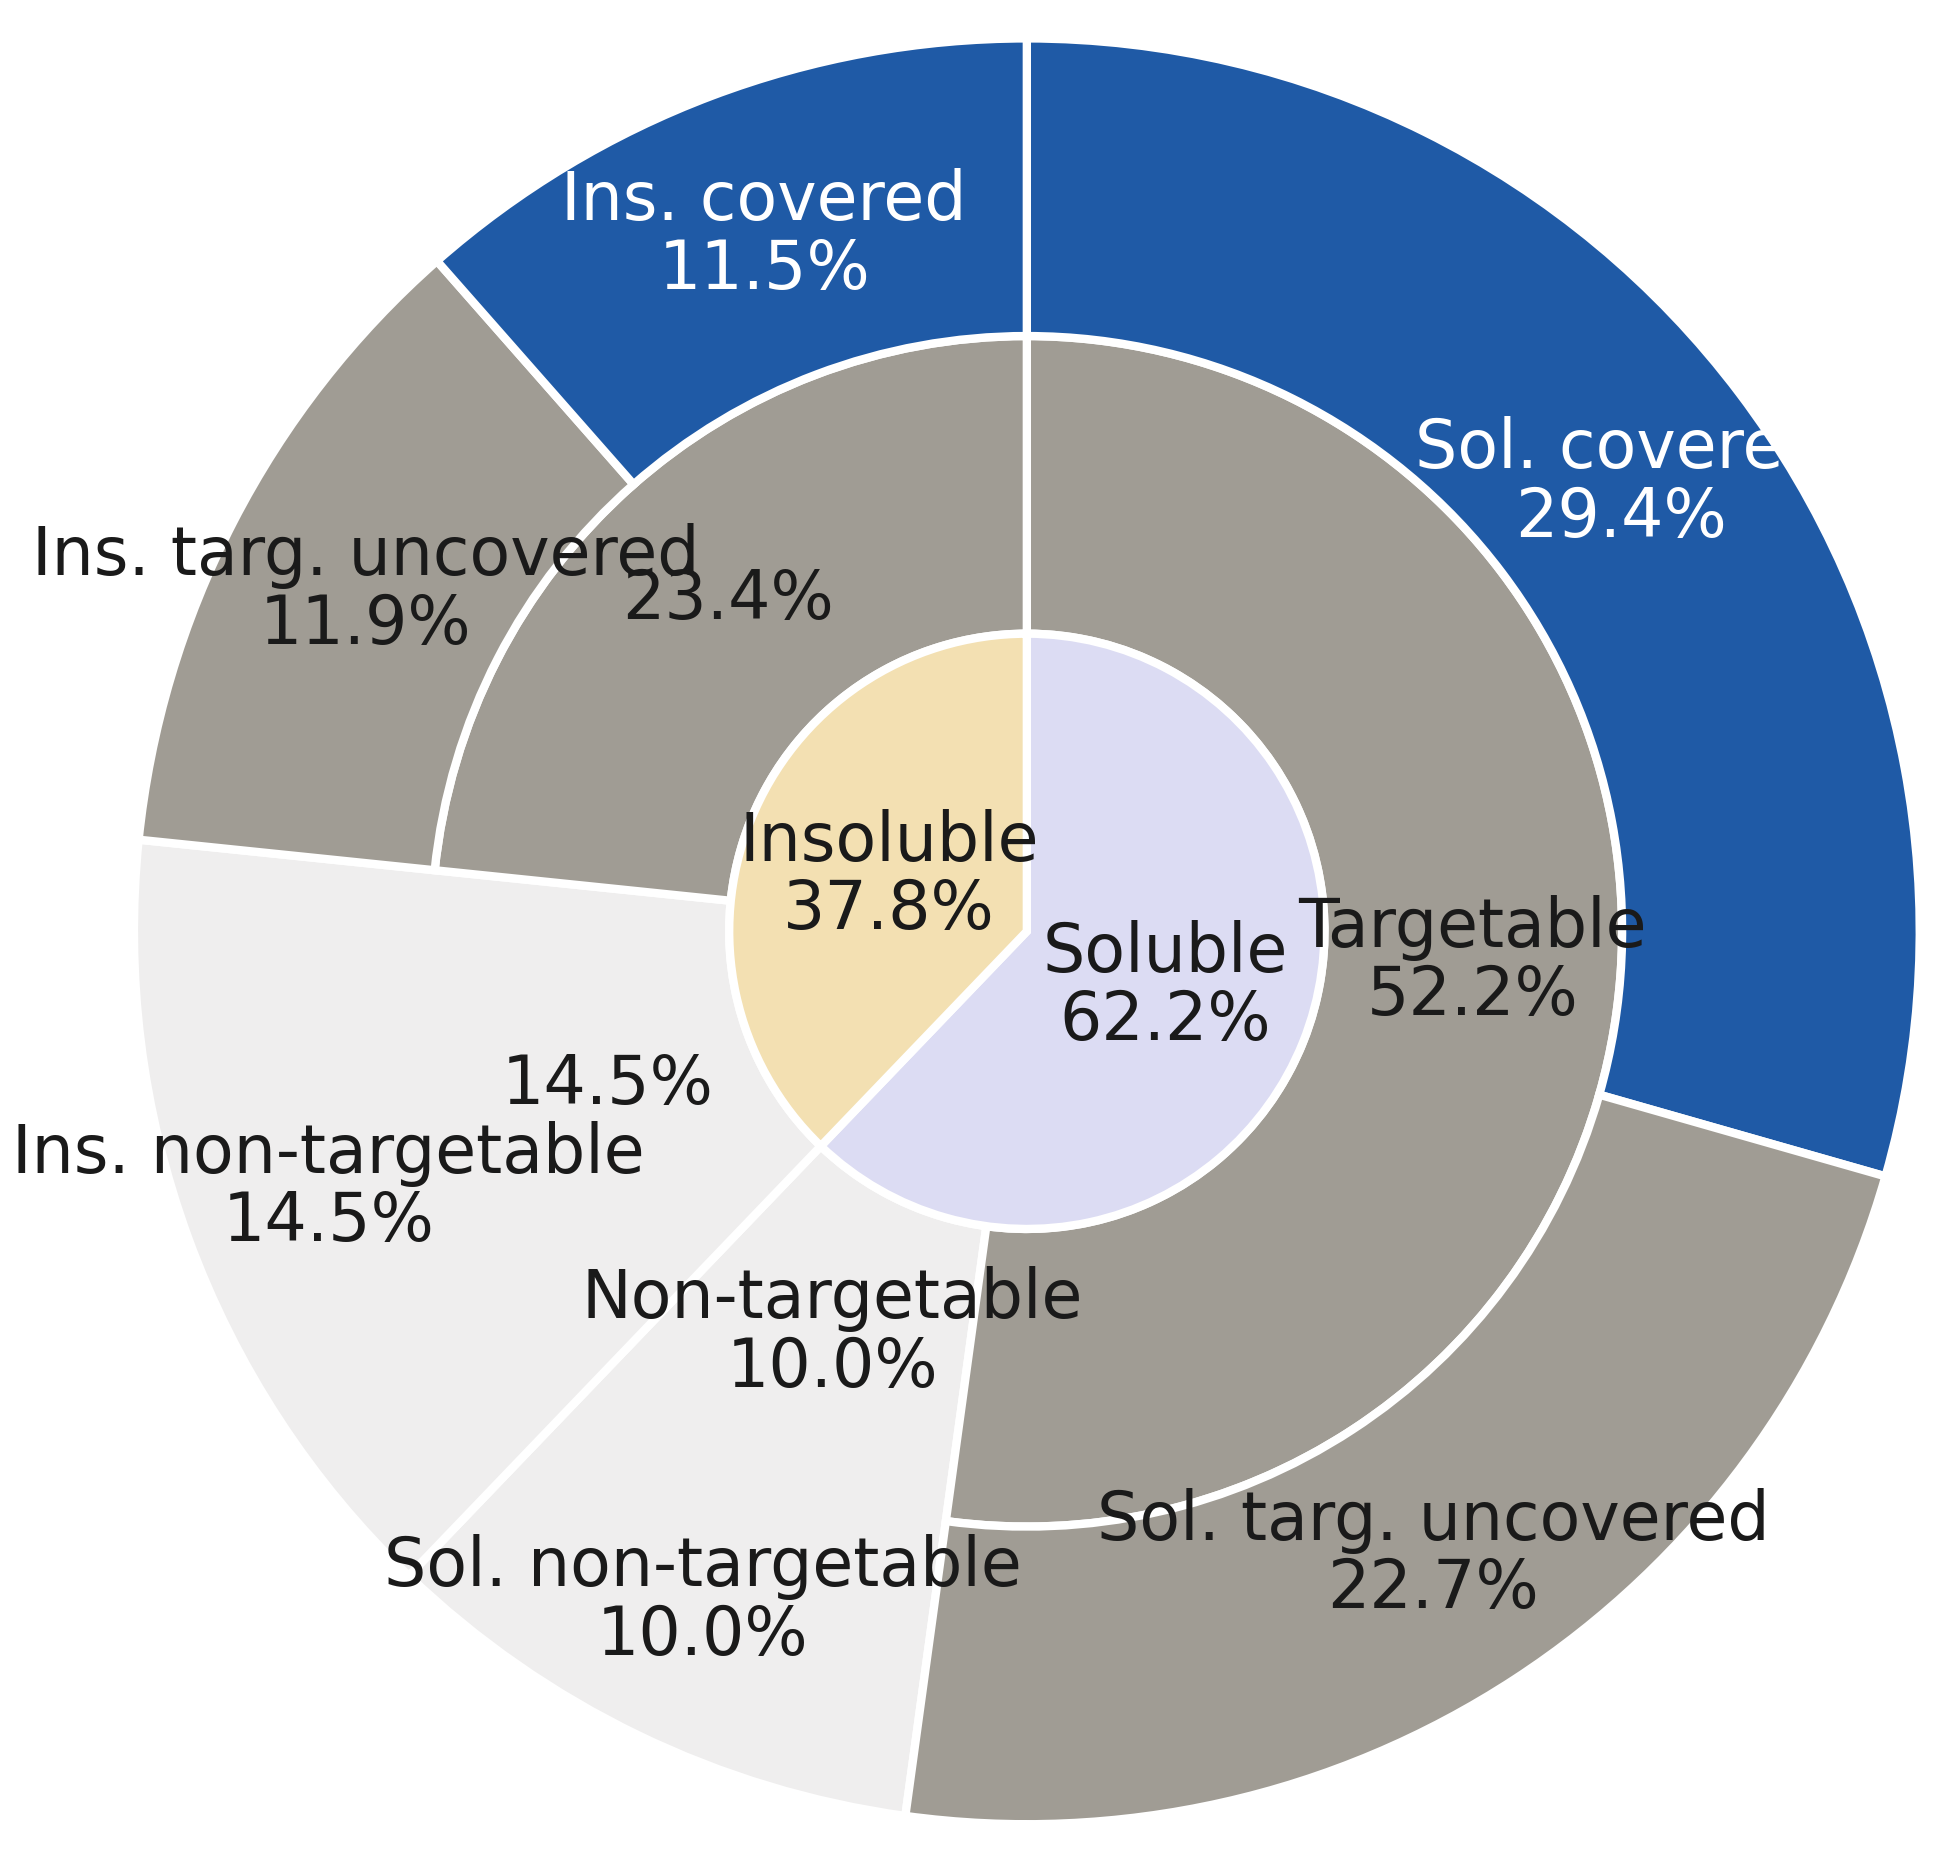


Hierarchy summary:
Soluble: 12607 | Insoluble: 7672
Soluble targetable/non-targetable: 10580 / 2027
Insoluble targetable/non-targetable: 4738 / 2934
Soluble covered/targ-uncovered: 5967 / 4613
Insoluble covered/targ-uncovered: 2329 / 2409


In [5]:
# Nested pie: proteome -> targetable -> covered, with the target line styling
import numpy as np
import matplotlib as mpl
import matplotlib.pyplot as plt
from matplotlib.patches import Wedge

# --- Core sets from the loaded dataframes (unchanged) ---
full_targets  = set(full_target_statistics_df['uniprot'].dropna().unique())
full_soluble  = set(full_target_statistics_df.loc[
    full_target_statistics_df['is_membrane_protein'] == False, 'uniprot'].dropna().unique())
full_insoluble = set(full_target_statistics_df.loc[
    full_target_statistics_df['is_membrane_protein'] == True, 'uniprot'].dropna().unique())

targetable = set(filtered_target_statistics_df['uniprot'].dropna().unique()) & full_targets
covered    = set(design_statistics_df['Target'].dropna().unique()) & targetable

covered_outside_full = set(design_statistics_df['Target'].dropna().unique()) - full_targets
if covered_outside_full:
    print(f"Warning: {len(covered_outside_full)} designed targets are not in "
          f"full_target_statistics_df and are excluded from this plot.")

# Soluble / insoluble partition by targetable then covered
sol_targ,   sol_untarg = full_soluble & targetable,  full_soluble - targetable
ins_targ,   ins_untarg = full_insoluble & targetable, full_insoluble - targetable
sol_cov,    sol_uncov  = sol_targ & covered,  sol_targ - covered
ins_cov,    ins_uncov  = ins_targ & covered,  ins_targ - covered

total = len(full_soluble) + len(full_insoluble)
def frac(s): return len(s) / max(1, total)
def pc(s):   return f"{100 * frac(s):.1f}%"

# --- Palette (same hues as before) ---
C_SOL  = mpl.colors.to_rgba('#8E8CD8', 0.3)   # inner: soluble  (light lavender)
C_INS  = mpl.colors.to_rgba('#D89B00', 0.3)   # inner: insoluble (light tan)
C_TARG = mpl.colors.to_rgba('#A09C94', 1.0)   # targetable & targ-uncovered (taupe)
C_NONT = mpl.colors.to_rgba('#CAC7C7', 0.3)   # non-targetable (light grey)
C_COV  = mpl.colors.to_rgba('#1F5AA6', 1.0)   # covered (blue)

# --- Geometry / styling ---
R          = 1.61      # ring width
startangle = 90.0      # soluble/insoluble split sits at 12 o'clock
LW         = 1.0       # white separator thickness
label_fontsize = 8

fig, ax = plt.subplots(figsize=(3.5, 3.5), dpi=600)
ax.set(aspect='equal'); ax.axis('off')
lim = 3 * R * 1.03
ax.set_xlim(-lim, lim); ax.set_ylim(-lim, lim)

wedge_kw = dict(edgecolor='white', linewidth=LW, antialiased=True)
def add_wedge(r_out, width, t1, t2, color):
    ax.add_patch(Wedge((0, 0), r_out, t1, t2, width=width, facecolor=color, **wedge_kw))
def put_label(r, t1, t2, text, white=False):
    th = np.deg2rad((t1 + t2) / 2.0)
    ax.text(r * np.cos(th), r * np.sin(th), text, ha='center', va='center',
            fontsize=label_fontsize, color=('white' if white else '#1a1a1a'), linespacing=1.05)

# Outer segments, clockwise from the top. Soluble block first, then insoluble,
# so the sol/ins split lines up radially across all three rings.
outer = [
    ('sol_cov', sol_cov,    C_COV,  'Sol. covered'),
    ('sol_tu',  sol_uncov,  C_TARG, 'Sol. targ. uncovered'),
    ('sol_nt',  sol_untarg, C_NONT, 'Sol. non-targetable'),
    ('ins_nt',  ins_untarg, C_NONT, 'Ins. non-targetable'),
    ('ins_tu',  ins_uncov,  C_TARG, 'Ins. targ. uncovered'),
    ('ins_cov', ins_cov,    C_COV,  'Ins. covered'),
]
meta = {k: (s, c, l) for k, s, c, l in outer}
ptr, span = startangle, {}
for k, s, c, l in outer:
    size = 360.0 * frac(s)
    span[k] = (ptr - size, ptr); ptr -= size

# 1) Non-targetable: ONE wedge across middle+outer  -> no line between those rings
for k in ('sol_nt', 'ins_nt'):
    add_wedge(3 * R, 2 * R, *span[k], C_NONT)

# 2) Middle "Targetable": one piece per side -> no covered/uncovered split shows here
sol_tspan = (span['sol_tu'][0],  span['sol_cov'][1])   # spans sol_cov + sol_tu
ins_tspan = (span['ins_cov'][0], span['ins_tu'][1])    # spans ins_tu + ins_cov
add_wedge(2 * R, R, *sol_tspan, C_TARG)
add_wedge(2 * R, R, *ins_tspan, C_TARG)

# 3) Outer covered + targ-uncovered -> these DO get the middle/outer line + radial split
for k in ('sol_cov', 'sol_tu', 'ins_tu', 'ins_cov'):
    add_wedge(3 * R, R, *span[k], meta[k][1])

# 4) Inner ring (soluble / insoluble)
sol_isp = (startangle - 360 * frac(full_soluble), startangle)
ins_isp = (startangle - 360, startangle - 360 * frac(full_soluble))
add_wedge(R, R, *sol_isp, C_SOL)
add_wedge(R, R, *ins_isp, C_INS)

# --- Labels (black, except white on the dark blue "covered" wedges for contrast;
# word only on the soluble side of the middle ring). Varying the text color also
# keeps each color run as a separate PDF text object under the cairo backend,
# so individual labels stay independently selectable/movable in Illustrator.
put_label(0.5 * R, *sol_isp, f"Soluble\n{pc(full_soluble)}")
put_label(0.5 * R, *ins_isp, f"Insoluble\n{pc(full_insoluble)}")
put_label(1.5 * R, *sol_tspan,      f"Targetable\n{pc(sol_targ)}")
put_label(1.5 * R, *ins_tspan,      f"{pc(ins_targ)}")
put_label(1.5 * R, *span['sol_nt'], f"Non-targetable\n{pc(sol_untarg)}")
put_label(1.5 * R, *span['ins_nt'], f"{pc(ins_untarg)}")
for k in ('sol_cov', 'sol_tu', 'sol_nt', 'ins_nt', 'ins_tu', 'ins_cov'):
    s, c, l = meta[k]
    put_label(2.5 * R, *span[k], f"{l}\n{pc(s)}", white=(k in ('sol_cov', 'ins_cov')))

plt.tight_layout()
finalize_figure(fig, 'proteome_coverage_nested_donut', dpi=600)

# Compact numerical summary
print('\nHierarchy summary:')
print(f"Soluble: {len(full_soluble)} | Insoluble: {len(full_insoluble)}")
print(f"Soluble targetable/non-targetable: {len(sol_targ)} / {len(sol_untarg)}")
print(f"Insoluble targetable/non-targetable: {len(ins_targ)} / {len(ins_untarg)}")
print(f"Soluble covered/targ-uncovered: {len(sol_cov)} / {len(sol_uncov)}")
print(f"Insoluble covered/targ-uncovered: {len(ins_cov)} / {len(ins_uncov)}")

# Stacked bars illustrating coverage

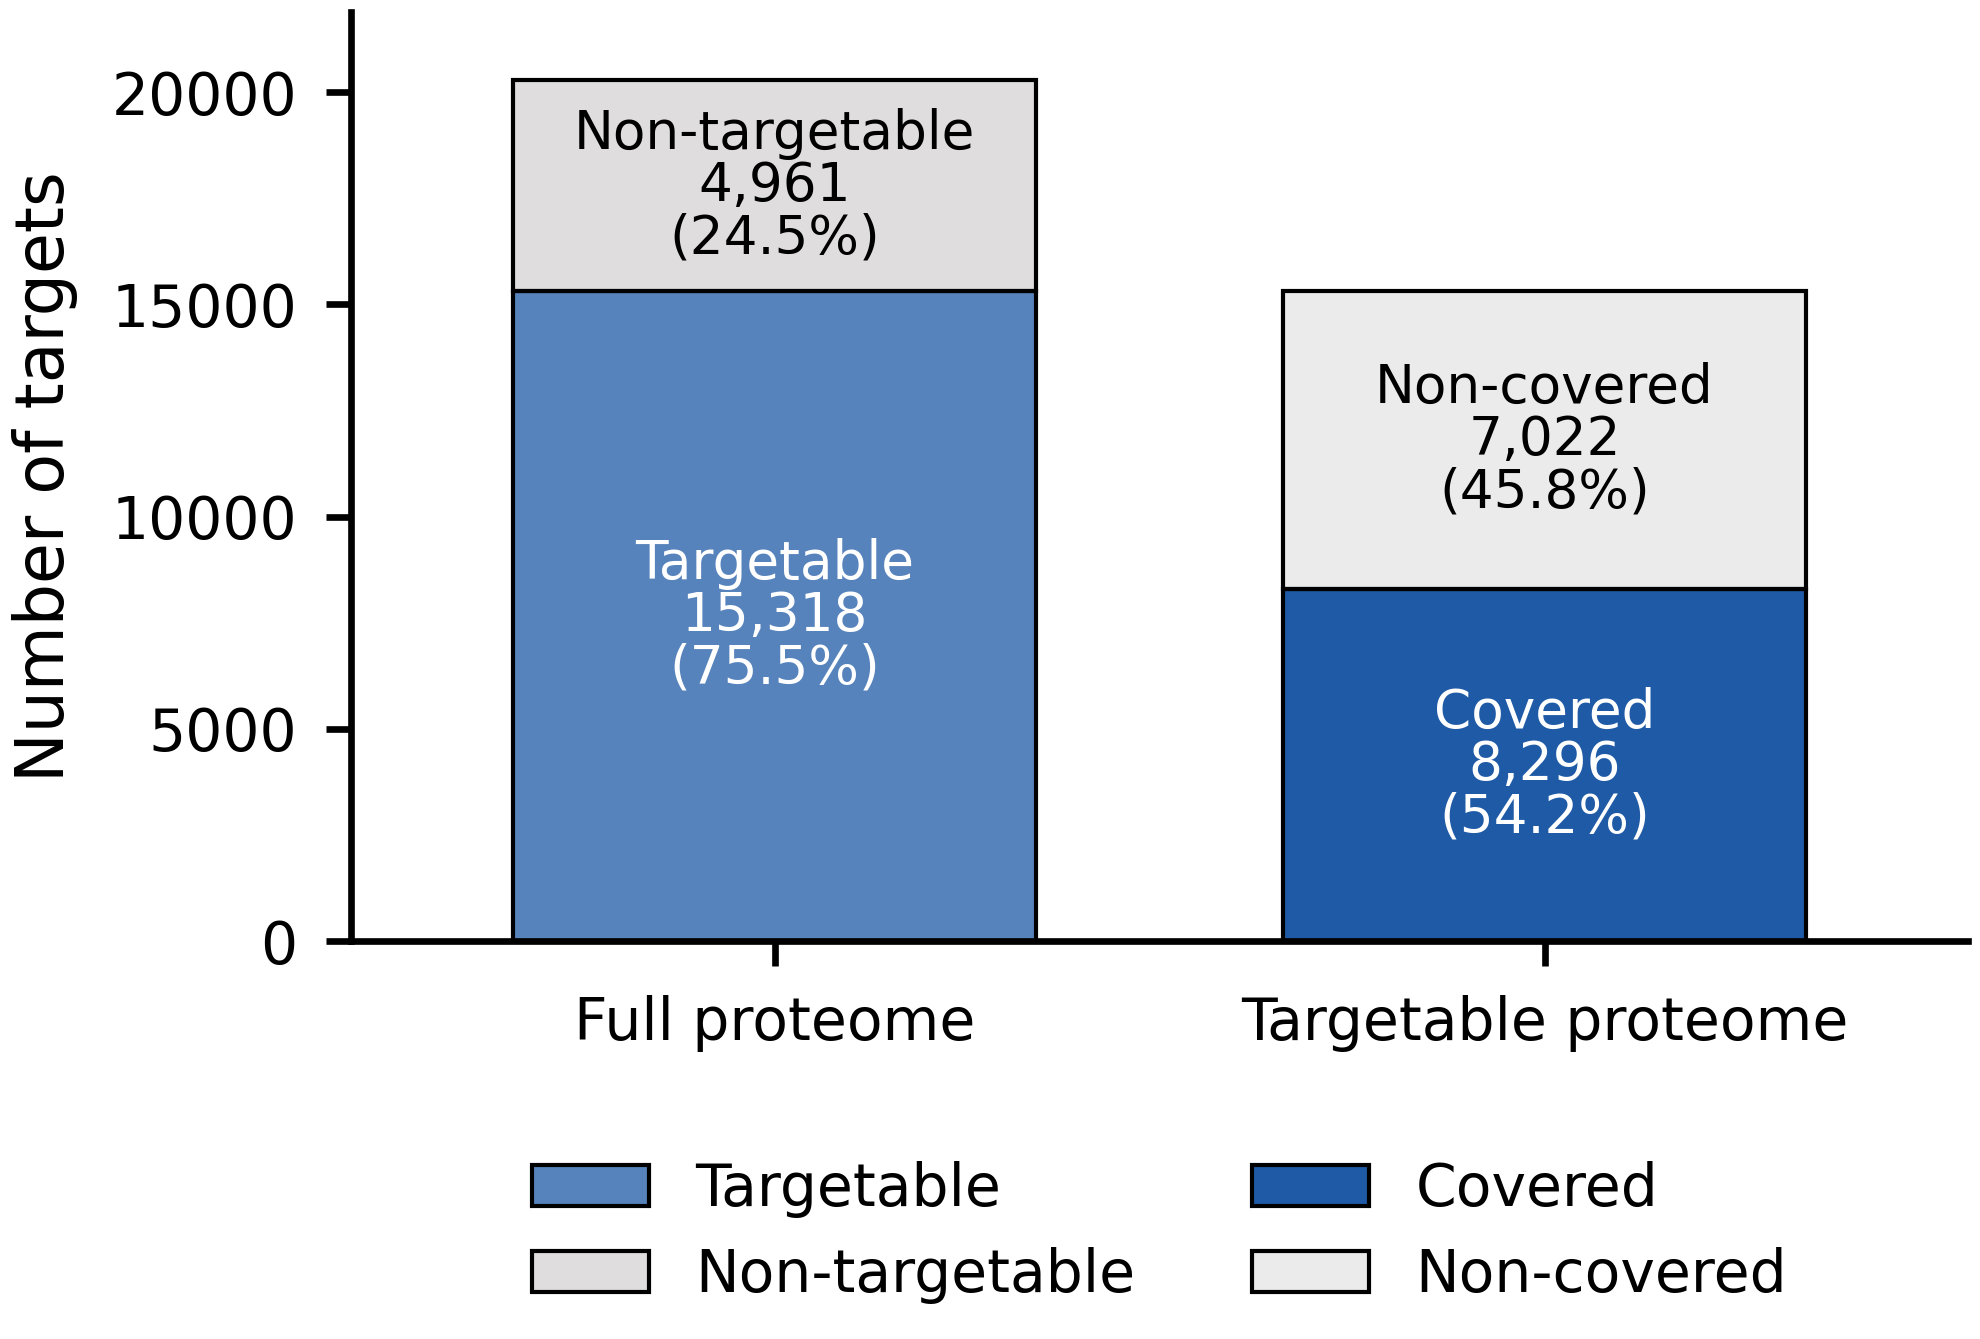

Stacked-bar summary:
Full proteome: 20279
Targetable / Non-targetable: 15318 / 4961
Covered / Non-covered (within targetable): 8296 / 7022


In [6]:
# Stacked bars for two-level coverage hierarchy (ignoring soluble/insoluble)
import numpy as np

# Recompute robustly from dataframes in case previous cells were not run in order
full_targets = set(full_target_statistics_df['uniprot'].dropna().unique())
targetable = set(filtered_target_statistics_df['uniprot'].dropna().unique()) & full_targets
covered = set(design_statistics_df['Target'].dropna().unique()) & targetable

n_full = len(full_targets)
n_targetable = len(targetable)
n_non_targetable = max(0, n_full - n_targetable)
n_covered = len(covered)
n_non_covered = max(0, n_targetable - n_covered)

fig, ax = plt.subplots(figsize=(3.5, 2.5), dpi=600)

x = np.array([0, 1])
bar_width = 0.68

targetable_color = mpl.colors.to_rgba("#1F5AA6", 0.75)
non_targetable_color = mpl.colors.to_rgba("#CAC7C7", 0.60)
covered_color = mpl.colors.to_rgba("#1F5AA6", 1.00)
non_covered_color = mpl.colors.to_rgba("#CAC7C7", 0.35)

# Bar 1: Full proteome = targetable + non-targetable
ax.bar(
    x[0],
    n_targetable,
    width=bar_width,
    color=targetable_color,
    edgecolor="black",
    linewidth=0.5,
    label="Targetable",
)
ax.bar(
    x[0],
    n_non_targetable,
    width=bar_width,
    bottom=n_targetable,
    color=non_targetable_color,
    edgecolor="black",
    linewidth=0.5,
    label="Non-targetable",
)

# Bar 2: Targetable proteome = covered + non-covered
ax.bar(
    x[1],
    n_covered,
    width=bar_width,
    color=covered_color,
    edgecolor="black",
    linewidth=0.5,
    label="Covered",
)
ax.bar(
    x[1],
    n_non_covered,
    width=bar_width,
    bottom=n_covered,
    color=non_covered_color,
    edgecolor="black",
    linewidth=0.5,
    label="Non-covered",
)

def _annotate_segment(xpos, bottom, height, text, color="black", fontsize=6.4):
    if height <= 0:
        return
    ax.text(
        xpos,
        bottom + 0.5 * height,
        text,
        ha="center",
        va="center",
        fontsize=fontsize,
        color=color,
        linespacing=1.0,
    )

full_den = max(1, n_full)
targetable_den = max(1, n_targetable)

_annotate_segment(
    x[0],
    0,
    n_targetable,
    f"Targetable\n{n_targetable:,}\n({100.0 * n_targetable / full_den:.1f}%)",
    color="white",
)
_annotate_segment(
    x[0],
    n_targetable,
    n_non_targetable,
    f"Non-targetable\n{n_non_targetable:,}\n({100.0 * n_non_targetable / full_den:.1f}%)",
    color="black",
)
_annotate_segment(
    x[1],
    0,
    n_covered,
    f"Covered\n{n_covered:,}\n({100.0 * n_covered / targetable_den:.1f}%)",
    color="white",
)
_annotate_segment(
    x[1],
    n_covered,
    n_non_covered,
    f"Non-covered\n{n_non_covered:,}\n({100.0 * n_non_covered / targetable_den:.1f}%)",
    color="black",
)

ax.set_xticks(x, labels=["Full proteome", "Targetable proteome"])
ax.set_ylabel("Number of targets")
ax.set_xlim(-0.55, 1.55)
ax.set_ylim(0, max(n_full, n_targetable, 1) * 1.08)

# Single legend with unique labels
handles, labels = ax.get_legend_handles_labels()
unique = dict(zip(labels, handles))
ax.legend(unique.values(), unique.keys(), loc="upper center", bbox_to_anchor=(0.5, -0.18), ncol=2, frameon=False)

plt.tight_layout()
finalize_figure(fig, "proteome_coverage_stacked_targetable_vs_covered", dpi=600)

print("Stacked-bar summary:")
print(f"Full proteome: {n_full}")
print(f"Targetable / Non-targetable: {n_targetable} / {n_non_targetable}")
print(f"Covered / Non-covered (within targetable): {n_covered} / {n_non_covered}")

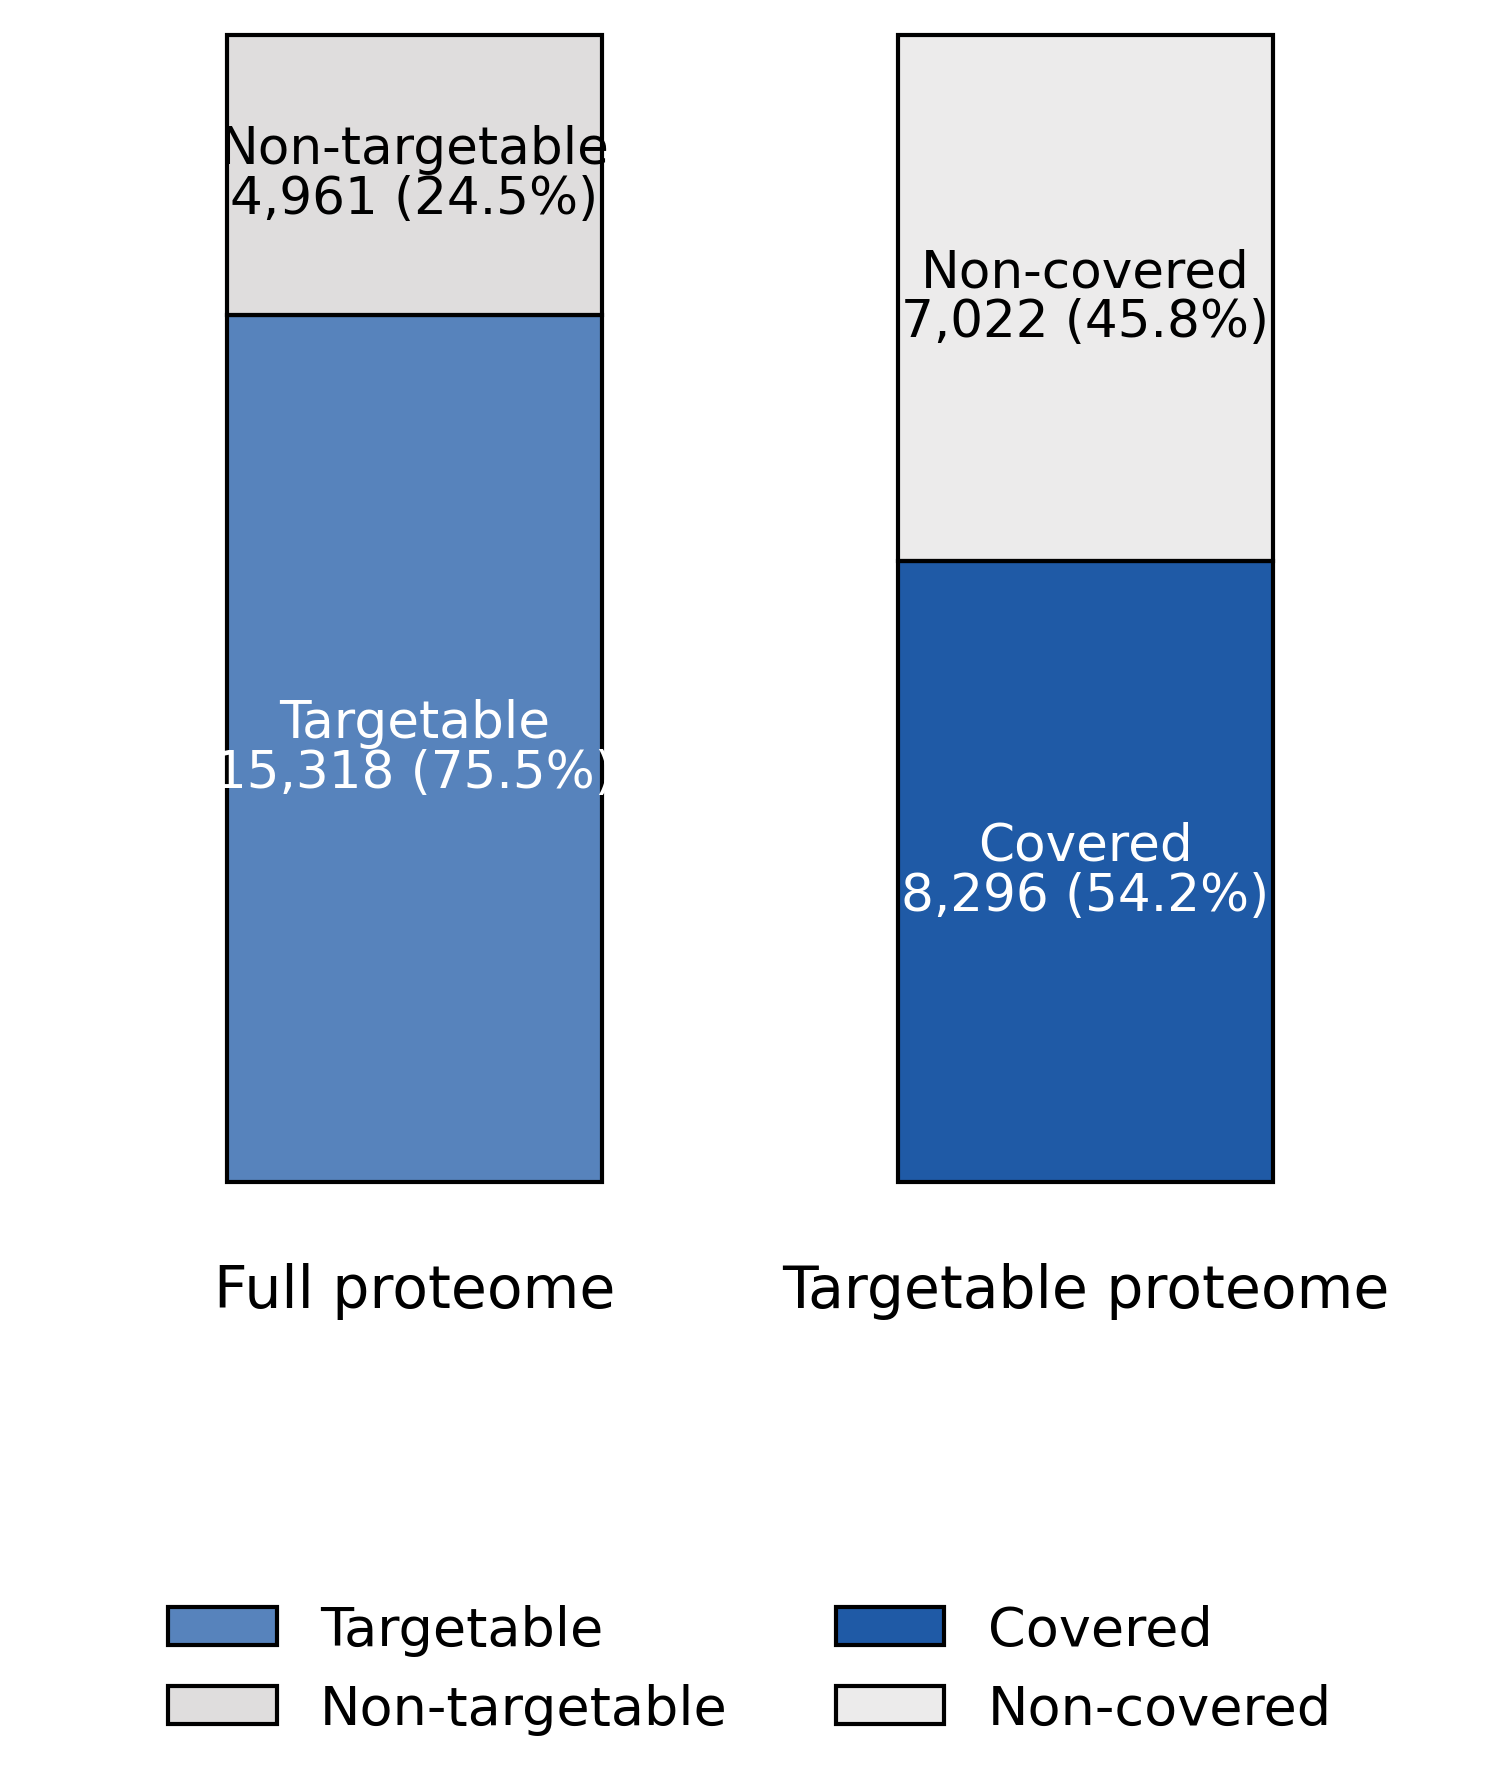

Axis-free proportional bars:
Full proteome targetable/non-targetable: 15318 / 4961
Targetable proteome covered/non-covered: 8296 / 7022


In [7]:
# Axis-free proportional vertical bars (no coordinate system)
import numpy as np

# Recompute robustly from dataframes
full_targets = set(full_target_statistics_df['uniprot'].dropna().unique())
targetable = set(filtered_target_statistics_df['uniprot'].dropna().unique()) & full_targets
covered = set(design_statistics_df['Target'].dropna().unique()) & targetable

n_full = len(full_targets)
n_targetable = len(targetable)
n_non_targetable = max(0, n_full - n_targetable)
n_covered = len(covered)
n_non_covered = max(0, n_targetable - n_covered)

full_den = max(1, n_full)
targetable_den = max(1, n_targetable)

# Fractions for proportional bar heights
frac_targetable = n_targetable / full_den
frac_non_targetable = n_non_targetable / full_den
frac_covered = n_covered / targetable_den
frac_non_covered = n_non_covered / targetable_den

fig, ax = plt.subplots(figsize=(2.7, 3.2), dpi=600)

x = np.array([0, 1])
bar_width = 0.56

targetable_color = mpl.colors.to_rgba("#1F5AA6", 0.75)
non_targetable_color = mpl.colors.to_rgba("#CAC7C7", 0.60)
covered_color = mpl.colors.to_rgba("#1F5AA6", 1.00)
non_covered_color = mpl.colors.to_rgba("#CAC7C7", 0.35)

# Bar 1: Full proteome split
ax.bar(
    x[0],
    frac_targetable,
    width=bar_width,
    color=targetable_color,
    edgecolor="black",
    linewidth=0.5,
    label="Targetable",
)
ax.bar(
    x[0],
    frac_non_targetable,
    width=bar_width,
    bottom=frac_targetable,
    color=non_targetable_color,
    edgecolor="black",
    linewidth=0.5,
    label="Non-targetable",
)

# Bar 2: Targetable proteome split
ax.bar(
    x[1],
    frac_covered,
    width=bar_width,
    color=covered_color,
    edgecolor="black",
    linewidth=0.5,
    label="Covered",
)
ax.bar(
    x[1],
    frac_non_covered,
    width=bar_width,
    bottom=frac_covered,
    color=non_covered_color,
    edgecolor="black",
    linewidth=0.5,
    label="Non-covered",
)

def _annotate_fraction(xpos, bottom, frac, label, count, text_color):
    if frac <= 0:
        return
    ax.text(
        xpos,
        bottom + 0.5 * frac,
        f"{label}\n{count:,} ({100.0 * frac:.1f}%)",
        ha="center",
        va="center",
        fontsize=6.2,
        color=text_color,
        linespacing=1.0,
    )

_annotate_fraction(x[0], 0, frac_targetable, "Targetable", n_targetable, "white")
_annotate_fraction(x[0], frac_targetable, frac_non_targetable, "Non-targetable", n_non_targetable, "black")
_annotate_fraction(x[1], 0, frac_covered, "Covered", n_covered, "white")
_annotate_fraction(x[1], frac_covered, frac_non_covered, "Non-covered", n_non_covered, "black")

# Category labels only (no axes/ticks/grid)
ax.text(x[0], -0.07, "Full proteome", ha="center", va="top", fontsize=7)
ax.text(x[1], -0.07, "Targetable proteome", ha="center", va="top", fontsize=7)

ax.set_xlim(-0.6, 1.6)
ax.set_ylim(-0.12, 1.02)
ax.set_xticks([])
ax.set_yticks([])
for spine in ax.spines.values():
    spine.set_visible(False)

# Keep a compact legend
handles, labels = ax.get_legend_handles_labels()
unique = dict(zip(labels, handles))
ax.legend(
    unique.values(),
    unique.keys(),
    loc="upper center",
    bbox_to_anchor=(0.5, -0.18),
    ncol=2,
    frameon=False,
    fontsize=6.5,
)

plt.tight_layout()
finalize_figure(fig, "proteome_coverage_stacked_targetable_vs_covered_no_axes", dpi=600)

print("Axis-free proportional bars:")
print(f"Full proteome targetable/non-targetable: {n_targetable} / {n_non_targetable}")
print(f"Targetable proteome covered/non-covered: {n_covered} / {n_non_covered}")

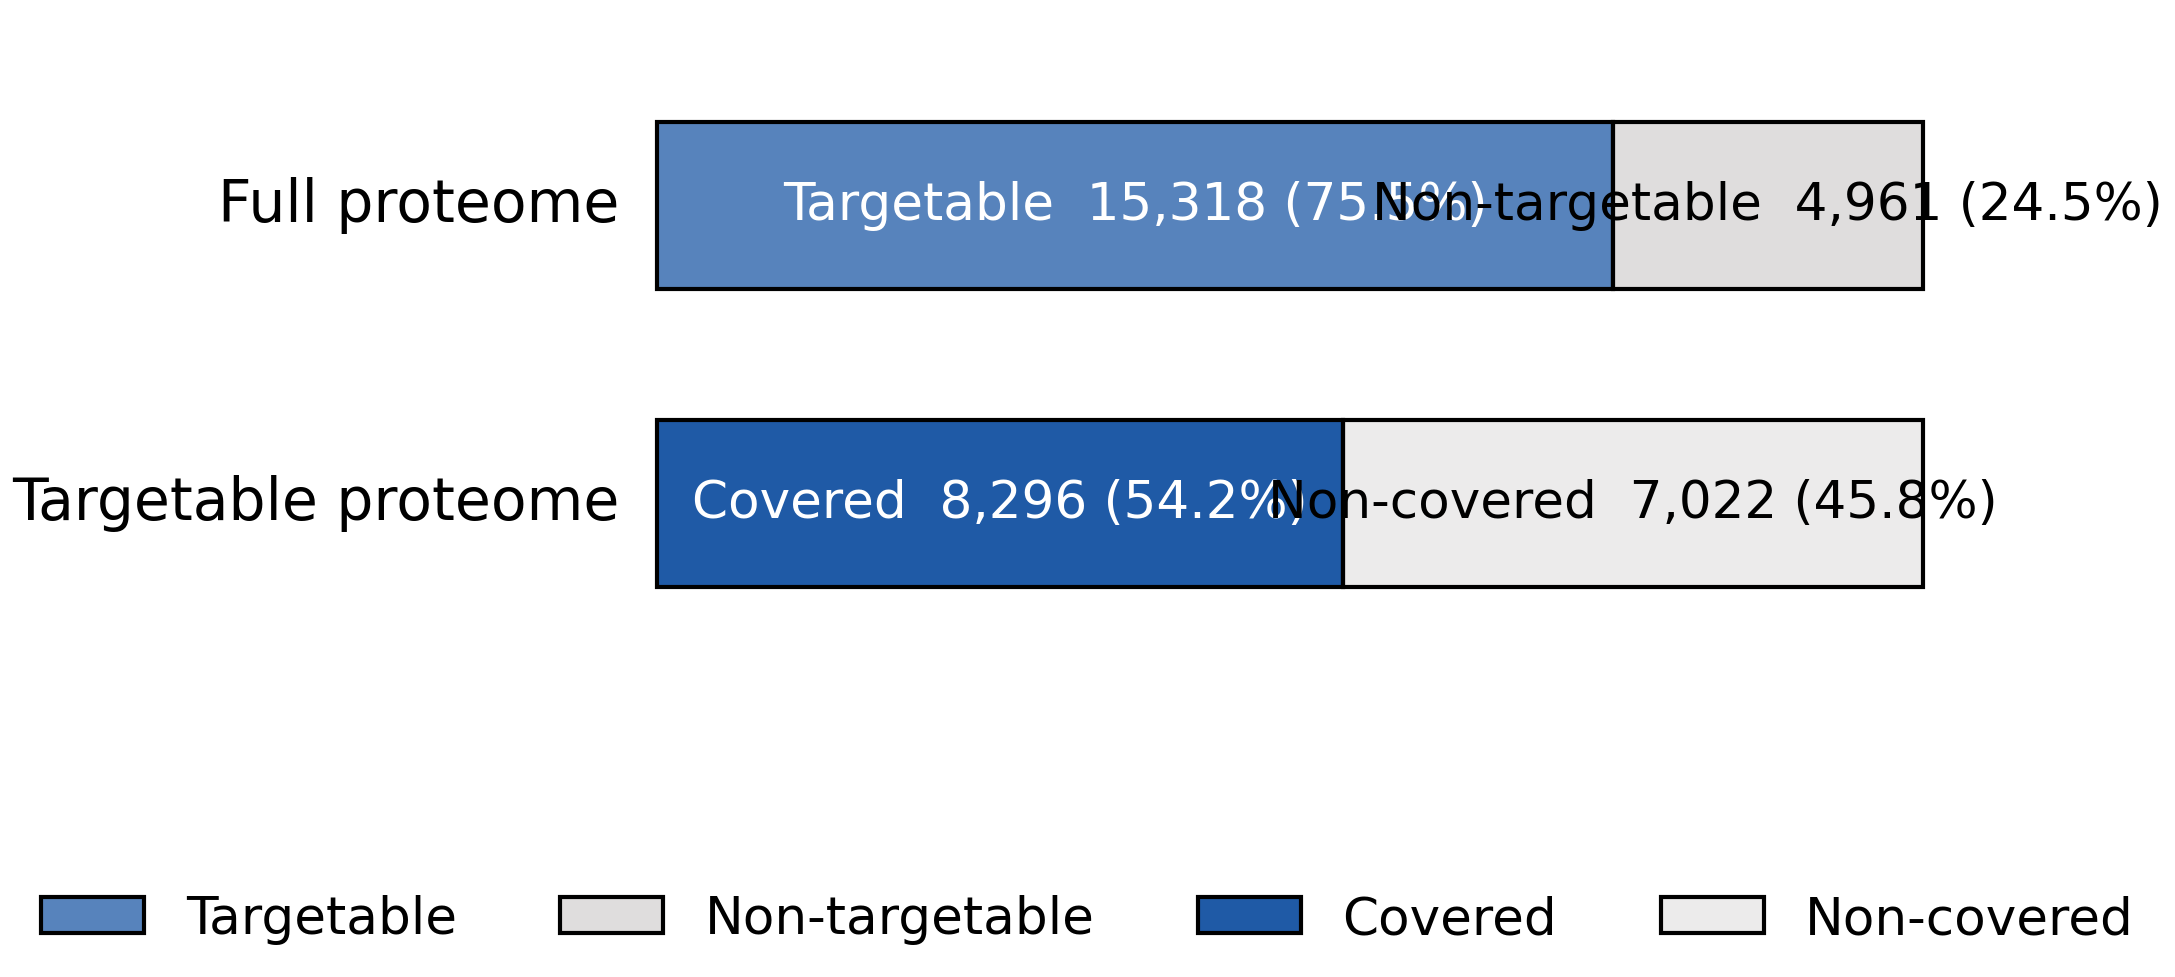

Horizontal axis-free proportional bars:
Full proteome targetable/non-targetable: 15318 / 4961
Targetable proteome covered/non-covered: 8296 / 7022


In [8]:
# Axis-free proportional horizontal bars
import numpy as np

# Recompute robustly from dataframes
full_targets = set(full_target_statistics_df['uniprot'].dropna().unique())
targetable = set(filtered_target_statistics_df['uniprot'].dropna().unique()) & full_targets
covered = set(design_statistics_df['Target'].dropna().unique()) & targetable

n_full = len(full_targets)
n_targetable = len(targetable)
n_non_targetable = max(0, n_full - n_targetable)
n_covered = len(covered)
n_non_covered = max(0, n_targetable - n_covered)

full_den = max(1, n_full)
targetable_den = max(1, n_targetable)

# Fractions for proportional bar lengths
frac_targetable = n_targetable / full_den
frac_non_targetable = n_non_targetable / full_den
frac_covered = n_covered / targetable_den
frac_non_covered = n_non_covered / targetable_den

fig, ax = plt.subplots(figsize=(3.8, 1.9), dpi=600)

# Top row: full proteome split | Bottom row: targetable split
y = np.array([1, 0])
bar_height = 0.56

targetable_color = mpl.colors.to_rgba("#1F5AA6", 0.75)
non_targetable_color = mpl.colors.to_rgba("#CAC7C7", 0.60)
covered_color = mpl.colors.to_rgba("#1F5AA6", 1.00)
non_covered_color = mpl.colors.to_rgba("#CAC7C7", 0.35)

# Row 1: targetable + non-targetable
ax.barh(
    y[0],
    frac_targetable,
    height=bar_height,
    color=targetable_color,
    edgecolor="black",
    linewidth=0.5,
    label="Targetable",
)
ax.barh(
    y[0],
    frac_non_targetable,
    left=frac_targetable,
    height=bar_height,
    color=non_targetable_color,
    edgecolor="black",
    linewidth=0.5,
    label="Non-targetable",
)

# Row 2: covered + non-covered
ax.barh(
    y[1],
    frac_covered,
    height=bar_height,
    color=covered_color,
    edgecolor="black",
    linewidth=0.5,
    label="Covered",
)
ax.barh(
    y[1],
    frac_non_covered,
    left=frac_covered,
    height=bar_height,
    color=non_covered_color,
    edgecolor="black",
    linewidth=0.5,
    label="Non-covered",
)

def _annotate_h_segment(x_left, y_pos, frac, label, count, text_color):
    if frac <= 0:
        return
    ax.text(
        x_left + 0.5 * frac,
        y_pos,
        f"{label}  {count:,} ({100.0 * frac:.1f}%)",
        ha="center",
        va="center",
        fontsize=6.2,
        color=text_color,
    )

_annotate_h_segment(0, y[0], frac_targetable, "Targetable", n_targetable, "white")
_annotate_h_segment(frac_targetable, y[0], frac_non_targetable, "Non-targetable", n_non_targetable, "black")
_annotate_h_segment(0, y[1], frac_covered, "Covered", n_covered, "white")
_annotate_h_segment(frac_covered, y[1], frac_non_covered, "Non-covered", n_non_covered, "black")

# Row labels (keep text only; no coordinate system)
ax.text(-0.03, y[0], "Full proteome", ha="right", va="center", fontsize=7)
ax.text(-0.03, y[1], "Targetable proteome", ha="right", va="center", fontsize=7)

ax.set_xlim(-0.34, 1.02)
ax.set_ylim(-0.65, 1.65)
ax.set_xticks([])
ax.set_yticks([])
for spine in ax.spines.values():
    spine.set_visible(False)

handles, labels = ax.get_legend_handles_labels()
unique = dict(zip(labels, handles))
ax.legend(
    unique.values(),
    unique.keys(),
    loc="upper center",
    bbox_to_anchor=(0.5, -0.22),
    ncol=4,
    frameon=False,
    fontsize=6.2,
)

plt.tight_layout()
finalize_figure(fig, "proteome_coverage_stacked_targetable_vs_covered_horizontal_no_axes", dpi=600)

print("Horizontal axis-free proportional bars:")
print(f"Full proteome targetable/non-targetable: {n_targetable} / {n_non_targetable}")
print(f"Targetable proteome covered/non-covered: {n_covered} / {n_non_covered}")

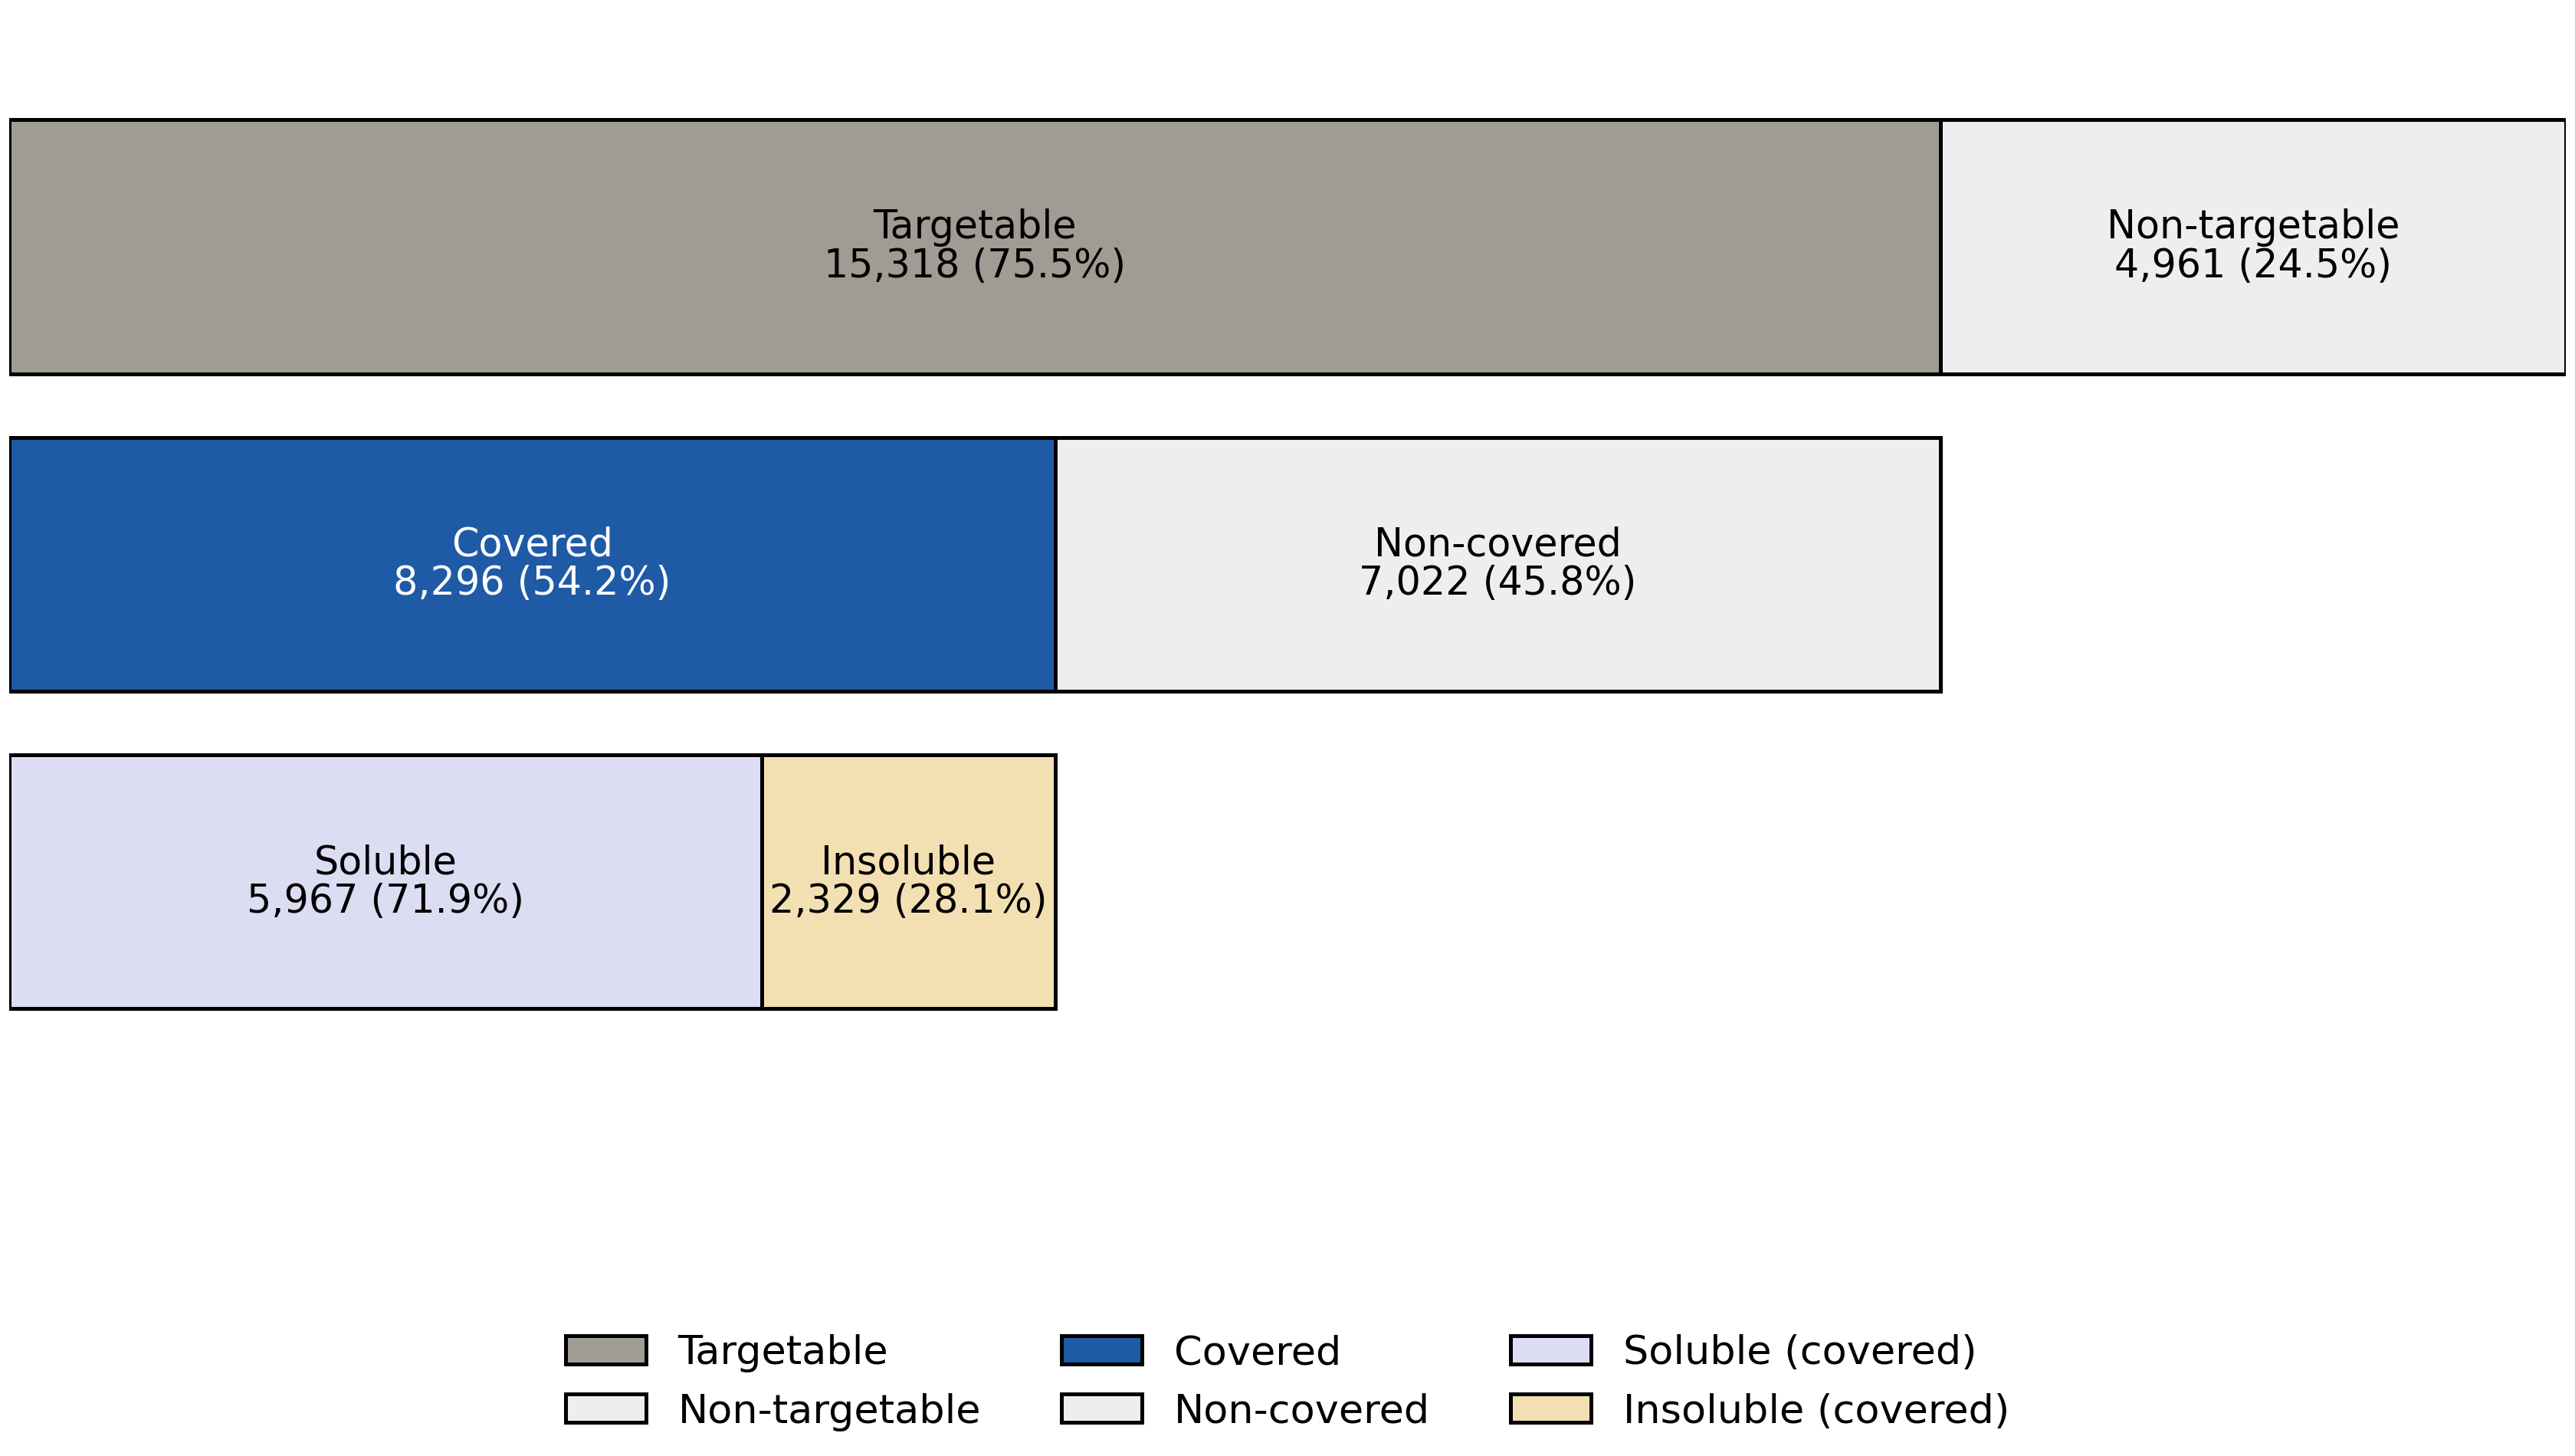

Horizontal stacked bars with covered row at the bottom:
Targetable / Non-targetable (full): 15318 / 4961
Covered / Non-covered (targetable): 8296 / 7022
Soluble / Insoluble (covered): 5967 / 2329


In [9]:
# Horizontal stacked bars with hierarchical rows:
# 1) Full (top): targetable vs non-targetable
# 2) Targetable (middle): covered vs non-covered
# 3) Covered (bottom): soluble vs insoluble
import numpy as np
import pandas as pd

full_targets = set(full_target_statistics_df['uniprot'].dropna().unique())
targetable = set(filtered_target_statistics_df['uniprot'].dropna().unique()) & full_targets
covered = set(design_statistics_df['Target'].dropna().unique()) & targetable

n_full = len(full_targets)
n_targetable = len(targetable)
n_non_targetable = max(0, n_full - n_targetable)
n_covered = len(covered)
n_non_covered = max(0, n_targetable - n_covered)

full_den = max(1, n_full)

# Covered split by membrane class (soluble vs insoluble)
def _as_bool(val):
    if pd.isna(val):
        return None
    if isinstance(val, (bool, np.bool_)):
        return bool(val)
    if isinstance(val, (int, float, np.integer, np.floating)):
        return bool(val)
    sval = str(val).strip().lower()
    if sval in {'true', 't', '1', 'yes', 'y'}:
        return True
    if sval in {'false', 'f', '0', 'no', 'n'}:
        return False
    return None

uniprot_membrane = (
    full_target_statistics_df[['uniprot', 'is_membrane_protein']]
    .dropna(subset=['uniprot'])
    .drop_duplicates(subset=['uniprot'])
    .set_index('uniprot')['is_membrane_protein']
)

n_covered_soluble = 0
n_covered_insoluble = 0
n_covered_unknown = 0
for target in covered:
    membrane_flag = _as_bool(uniprot_membrane.get(target, np.nan))
    if membrane_flag is True:
        n_covered_insoluble += 1
    elif membrane_flag is False:
        n_covered_soluble += 1
    else:
        n_covered_unknown += 1

# Keep two sections in covered row; fold unknown into insoluble
if n_covered_unknown > 0:
    n_covered_insoluble += n_covered_unknown

# Widths normalized to full proteome so hierarchy is preserved across rows
w_targetable = n_targetable / full_den
w_non_targetable = n_non_targetable / full_den
w_covered = n_covered / full_den
w_non_covered = n_non_covered / full_den
w_covered_soluble = n_covered_soluble / full_den
w_covered_insoluble = n_covered_insoluble / full_den

fig, ax = plt.subplots(figsize=(5.8, 3.4), dpi=600)

y = np.array([2.0, 1.0, 0.0])
bar_height = 0.80

# Match the exact palette used in the top nested-donut chart
# Inner ring: soluble/insoluble
soluble_color = mpl.colors.to_rgba('#8E8CD8', 0.30)
insoluble_color = mpl.colors.to_rgba('#D89B00', 0.30)
# Middle ring: targetable/non-targetable
targetable_color = mpl.colors.to_rgba('#A09C94', 1.00)
non_targetable_color = mpl.colors.to_rgba('#CAC7C7', 0.30)
# Outer ring: covered/non-covered
covered_color = mpl.colors.to_rgba('#1F5AA6', 1.00)
non_covered_color = mpl.colors.to_rgba('#CAC7C7', 0.30)

# Row 1: Full proteome
ax.barh(y[0], w_targetable, height=bar_height, color=targetable_color, edgecolor='black', linewidth=0.6, label='Targetable')
ax.barh(y[0], w_non_targetable, left=w_targetable, height=bar_height, color=non_targetable_color, edgecolor='black', linewidth=0.6, label='Non-targetable')

# Row 2: Targetable proteome
ax.barh(y[1], w_covered, height=bar_height, color=covered_color, edgecolor='black', linewidth=0.6, label='Covered')
ax.barh(y[1], w_non_covered, left=w_covered, height=bar_height, color=non_covered_color, edgecolor='black', linewidth=0.6, label='Non-covered')

# Row 3: Covered proteome
ax.barh(y[2], w_covered_soluble, height=bar_height, color=soluble_color, edgecolor='black', linewidth=0.6, label='Soluble (covered)')
ax.barh(y[2], w_covered_insoluble, left=w_covered_soluble, height=bar_height, color=insoluble_color, edgecolor='black', linewidth=0.6, label='Insoluble (covered)')

def _label_segment(x_left, y_pos, width, text, color='black'):
    if width <= 0:
        return
    ax.text(x_left + 0.5 * width, y_pos, text, ha='center', va='center', fontsize=6.1, color=color, linespacing=1.02)

# Percentages shown are within each row context
pct_targetable = 100.0 * n_targetable / max(1, n_full)
pct_non_targetable = 100.0 * n_non_targetable / max(1, n_full)
pct_covered = 100.0 * n_covered / max(1, n_targetable)
pct_non_covered = 100.0 * n_non_covered / max(1, n_targetable)
pct_covered_soluble = 100.0 * n_covered_soluble / max(1, n_covered)
pct_covered_insoluble = 100.0 * n_covered_insoluble / max(1, n_covered)

# All annotations inside bars only
_label_segment(0.0, y[0], w_targetable, f'Targetable\n{n_targetable:,} ({pct_targetable:.1f}%)', color='black')
_label_segment(w_targetable, y[0], w_non_targetable, f'Non-targetable\n{n_non_targetable:,} ({pct_non_targetable:.1f}%)', color='black')

_label_segment(0.0, y[1], w_covered, f'Covered\n{n_covered:,} ({pct_covered:.1f}%)', color='white')
_label_segment(w_covered, y[1], w_non_covered, f'Non-covered\n{n_non_covered:,} ({pct_non_covered:.1f}%)', color='black')

_label_segment(0.0, y[2], w_covered_soluble, f'Soluble\n{n_covered_soluble:,} ({pct_covered_soluble:.1f}%)', color='black')
_label_segment(w_covered_soluble, y[2], w_covered_insoluble, f'Insoluble\n{n_covered_insoluble:,} ({pct_covered_insoluble:.1f}%)', color='black')

# Axis-free presentation
ax.set_xlim(0.0, 1.0)
ax.set_ylim(-0.75, 2.75)
ax.set_xticks([])
ax.set_yticks([])
for spine in ax.spines.values():
    spine.set_visible(False)

handles, labels = ax.get_legend_handles_labels()
unique = dict(zip(labels, handles))
ax.legend(unique.values(), unique.keys(), loc='upper center', bbox_to_anchor=(0.5, -0.16), ncol=3, frameon=False, fontsize=6.3)

plt.tight_layout()
finalize_figure(fig, 'proteome_coverage_stacked_text_fit_boxes', dpi=600)

print('Horizontal stacked bars with covered row at the bottom:')
print(f'Targetable / Non-targetable (full): {n_targetable} / {n_non_targetable}')
print(f'Covered / Non-covered (targetable): {n_covered} / {n_non_covered}')
print(f'Soluble / Insoluble (covered): {n_covered_soluble} / {n_covered_insoluble}')
if n_covered_unknown > 0:
    print(f'Note: {n_covered_unknown} covered targets with unknown membrane status were counted in Insoluble.')